![Banner](../images/09_11_banner_rs_foundation_models.png)

# What Foundation Models Are and Why Remote Sensing Needs Them

A foundation model is a large network trained once, without labels, on a very large and varied
archive, and then reused for many tasks. Earth observation is a natural fit: satellites deliver
petabytes of imagery every year, while labelled samples stay scarce, expensive and local. This
notebook explains how remote sensing foundation models are trained, what makes satellite data
different from photographs, the ways a pretrained model can be used, and what the published
benchmarks say about them. It then tours the 45 models in `geolattice.rsense.foundation_models` and
turns a Sentinel-2 image of a university campus into embeddings with one of them.

Fourteen notebooks take a pretrained model from that idea to a benchmark on your own data.

- **What Foundation Models Are and Why Remote Sensing Needs Them.** This notebook. How these models are trained, what makes satellite data different from photographs, and a first embedding of a Sentinel-2 campus scene.
- **Self-supervised pretraining for Sentinel-2 crop mapping.** SimCLR, MoCo with seasonal views, and a masked autoencoder on unlabeled Iowa Sentinel-2, scored with a linear probe against the Cropland Data Layer.
- **Geospatial foundation models: embeddings, promptable segmentation and zero-shot classification.** Prithvi, DOFA, Segment Anything, and RemoteCLIP, each scored against reference labels.
- **From a GeoTIFF to an Embedding Map.** Bands, units, normalization, and chip size for a Sentinel-2 scene of the Iowa Corn Belt, then the embedding map.
- **Prithvi, SSL4EO, SatlasPretrain and Scale-MAE on Sentinel-2.** Four optical encoders on the same Iowa Corn Belt scenes.
- **One Model for Many Sensors: DOFA, Panopticon, Copernicus-FM, CROMA and TerraMind.** Sentinel-2, Landsat 8, and Sentinel-1 of the same Iowa fields, and whether a classifier trained on one sensor transfers.
- **Time in Foundation Models: Prithvi-TL, AnySat, Presto and Galileo.** One to four Sentinel-2 dates of the 2025 Iowa season, with and without date and location inputs.
- **AlphaEarth Foundations: Precomputed Embeddings for the Whole Planet.** A 64-band, 10 m embedding already computed for every land pixel, every year since 2017.
- **Foundation Model Embeddings as Covariates: Digital Soil Mapping of SOC.** Topsoil organic carbon mapped with embeddings used as covariates.
- **Very High Resolution: DINOv3-sat, Satlas NAIP, Scale-MAE and SAM 2.** Roofs, trees, and field boundaries on a 1.6 m WorldView-2 scene and 50 cm DeepGlobe images.
- **Vision-Language Models: Zero-Shot Classification and Text Retrieval.** RemoteCLIP and GeoRSCLIP on EuroSAT, and how the wording of the class descriptions changes the score.
- **Change and Similarity in Embedding Space.** The 2026 Bug Fire from pre-fire and post-fire Sentinel-2 embeddings, scored against the fire perimeter and dNBR.
- **Weather and Earth System Foundation Models.** Learned weather models compared, then Aurora on ERA5 from WeatherBench2.
- **Benchmarking Foundation Models on Your Own Data.** One harness for EuroSAT scene classification and early-season corn and soybean mapping.


## Overview

### From one model per task to one model for many tasks

A classical workflow trains a new model for every map: a random forest for crop types in Iowa, a
U-Net for buildings in Dhaka, another network for floods. Each needs its own labels and learns
the basic structure of satellite imagery (what a field edge, a river or a road looks like) from
scratch. A **foundation model** separates the two. It first learns general visual and spectral
structure from unlabelled imagery (**pretraining**), then a small labelled set adapts it to a
task (**transfer**). The pretrained network is called an **encoder** or **backbone**, and the
vector it returns for an image or a patch is an **embedding**.

The name comes from Bommasani et al. (2021): a model trained on broad data that can be adapted
to a wide range of downstream tasks. "Foundation" says nothing about accuracy. A foundation
model can be worse than a well tuned random forest on a given task, and the benchmarks below
show that this happens.

### Why labels are the bottleneck in Earth observation

- Field data are slow to collect and rarely shared; labels from one region or year often do not
  transfer to another.
- Reference maps such as the USDA Cropland Data Layer exist for few countries and few classes.
- The imagery itself is abundant and free: Sentinel-2 alone images every land surface every five
  days at 10 to 60 m.

Pretraining moves most of the learning onto the free part (imagery) so that the expensive part
(labels) is needed only for the last step.

### How remote sensing foundation models are pretrained

| Objective | Idea | Examples in GeoLattice |
|---|---|---|
| Masked autoencoding (MAE) | Hide most image patches and reconstruct them from the rest | Prithvi-EO, SatMAE, Scale-MAE, Clay, DOFA |
| Contrastive learning | Pull two views of the same place together, push other places apart | SSL4EO MoCo, CROMA (optical vs SAR views) |
| Self-distillation | A student network matches a slowly updated teacher on different crops | SSL4EO DINO, DINOv3-sat, Panopticon |
| Joint embedding prediction (JEPA) | Predict the embedding of hidden parts instead of their pixels | AnySat, Galileo |
| Generative any-to-any | Generate one modality (SAR, DEM, land cover) from another | TerraMind |
| Image-text alignment | Match images with their captions | RemoteCLIP, GeoRSCLIP, SkyCLIP |
| Embedding fields | Summarize a year of many sensors into one vector per pixel | AlphaEarth Foundations |

Notebook 09_11_01 trains SimCLR, MoCo and a masked autoencoder at small scale, so this notebook
keeps the theory short and shows what two of the objectives see.

### What makes satellite imagery different

1. **Many bands.** Sentinel-2 has 13, Landsat 11, hyperspectral sensors hundreds, and SAR records
   polarizations instead of colours. A network pretrained on red, green and blue photographs has
   no input for the shortwave infrared.
2. **Many sensors.** A model trained on Sentinel-2 should not silently accept WorldView-2 bands in
   the same order. **Wavelength-conditioned** input layers (DOFA, Copernicus-FM, Panopticon)
   build their first layer from the band wavelengths, so one model accepts any band set.
3. **Ground sample distance (GSD).** The same 224 pixel chip covers 2 km of Sentinel-2 or 70 m of
   aerial imagery. Scale-MAE encodes the GSD in its position encoding.
4. **Time.** Crops, snow and floods are defined by change through a season. Prithvi-EO-2.0 takes
   several dates as a 3-D input and can add date and location tokens (the TL variants).
5. **Geolocation.** Every pixel has coordinates, so models can use location, and evaluation must
   keep training and test areas apart (spatial autocorrelation).
6. **Archive size.** SSL4EO-S12 holds about 3 million Sentinel-1 and Sentinel-2 patches, SatlasPretrain
   302 million labels, DINOv3-sat 493 million Maxar images.

### Tokens, patches and embeddings

Vision transformers (ViT) cut an image into square **patches**, usually 16 by 16 pixels, and turn
each patch into a **token** vector. A 224 pixel chip therefore becomes 14 x 14 = 196 tokens,
often plus one **class token** (CLS) that summarizes the whole chip. The model returns:

- **patch embeddings**: one vector per patch, a coarse feature map (14 x 14 for a 224 chip);
- **image embeddings**: one vector per chip, either the CLS token or the mean of the patch tokens;
- **pixel embeddings**: per-pixel products such as AlphaEarth, or patch features upsampled to pixels.

The **embedding dimension** is the length of the vector: 384 to 1280 for the ViTs here, 512 or
2048 for ResNets, 64 for AlphaEarth.

### Ways to use a foundation model

| Use | Labels needed | Compute | Typical result |
|---|---|---|---|
| Frozen embeddings + simple model (linear probe, kNN, random forest) | few to moderate | inference only | quick baseline, good for similarity and clustering |
| Partial or full fine-tuning | moderate | training on a GPU | best accuracy when labels suffice |
| Encoder + segmentation decoder | pixel masks | training | land cover, crops, floods (TerraTorch) |
| Zero-shot with text | none | inference | scene labels from words; must be checked |
| Precomputed embedding products | few | none locally | AlphaEarth: covariates without running a model |

A **linear probe** trains only a linear classifier on frozen embeddings. It is the standard way to
ask "how much does the encoder already know?", and this chapter uses it throughout.

### What the benchmarks say

GEO-Bench (Lacoste et al. 2023) and PANGAEA (Marsocci et al. 2024) compare many models on the same
tasks with the same protocol. Two findings matter in practice: no model is best on every task,
and a supervised U-Net trained on the task data is a strong baseline that several foundation models
do not beat, especially when enough labels exist or the target sensor differs from the pretraining
data. Gains are largest with few labels and with data close to the pretraining distribution. Every
comparison in this chapter therefore keeps a simple baseline and uses spatial cross-validation.

### Licences and compute

Weights come with licences that range from Apache 2.0 and CC BY to research-only and gated access
(DINOv3-sat). Always read the model card before using a model in a product. Pretraining needs large
GPU clusters, but inference does not: every model in this chapter runs on one 16 GB GPU, and the
smaller ones on a CPU.

## Foundation Models with GeoLattice

`geolattice.rsense.foundation_models` (imported as `fm`) gives every model one interface:

| Function | Purpose |
|---|---|
| `fm.list_models`, `fm.model_info`, `fm.CATEGORIES` | the catalog of 45 models |
| `fm.recommend(task, sensor=)` | models to try first for a task |
| `fm.load_model(name, bands=)` | download and wrap a model as a `FoundationEncoder` |
| `enc.encode`, `enc.embed`, `enc.embed_raster` | embeddings for tensors, arrays or georeferenced rasters |
| `fm.linear_probe`, `fm.knn_probe`, `fm.similarity_map`, `fm.cluster_embeddings` | what the embeddings know |

### Learning objectives

1. Explain pretraining, transfer, encoders, tokens and embeddings.
2. Name the main pretraining objectives and what makes satellite data different from photographs.
3. Choose between frozen embeddings, fine-tuning, zero-shot and embedding products.
4. Browse the catalog by category, modality and year, and get recommendations for a task.
5. Load a wavelength-aware model and turn a Sentinel-2 image into patch embeddings.
6. Check what the embeddings separate with a quick PCA view and a linear probe.

### Data

| Dataset | Content |
|---|---|
| UB North Campus Sentinel-2 | 10 bands (B2 to B12), 10 m, 170 x 210 pixels, Buffalo, New York (UTM 17N) |
| UB labelled points | 23,945 pixels in five land use classes: tree/bushes, parking/road/pavement, grass, building, water |

### Contents

- Setup
- What two pretraining objectives see
- The model catalog
- Choosing a model for a task
- From an image to patch embeddings
- What the embeddings separate
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `geolattice[rsense-foundation]`, which no GeoLattice option installs: `pip install "geolattice[rsense-foundation]"`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import time  # timing
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: every model runs on it
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.foundation_models as fm  # catalog, loaders, embeddings and probes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing")  # remote sensing data folder
IC = DATA / "09_09_image_classification"  # data shared with the image classification chapter
CAP = DATA / "08_11_Capstones"  # data shared with the capstones
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # run models on the GPU when there is one
SEED = 0  # one seed for every random step
np.random.seed(SEED)  # NumPy
torch.manual_seed(SEED)  # PyTorch

print("GeoLattice", geolattice.__version__, "| PyTorch", torch.__version__, "| device", DEVICE)  # versions used
if DEVICE == "cuda":  # name the GPU
    print("GPU:", torch.cuda.get_device_name(0))  # GPU model

UB = IC / "Sentinel_2_UB"  # UB North Campus Sentinel-2 bands and labelled points
BANDS = {"B2": "blue", "B3": "green", "B4": "red", "B5": "rededge1", "B6": "rededge2",
         "B7": "rededge3", "B8": "nir", "B8A": "nir08", "B11": "swir16", "B12": "swir22"}  # file -> band name

GeoLattice 0.3.47 | PyTorch 2.14.0+cu132 | device cuda
GPU: NVIDIA RTX A5500 Laptop GPU


## What two pretraining objectives see

The UB North Campus image is read band by band into one `(band, y, x)` DataArray. The GeoTIFFs
store reflectance multiplied by 10,000 and carry no CRS, so the UTM zone 17N CRS of the labelled
points is attached.

In [2]:
ub = xr.concat([rioxarray.open_rasterio(UB / "Images" / f"{f}.tif").squeeze("band", drop=True)
                for f in BANDS], dim=pd.Index(list(BANDS.values()), name="band"))  # 10-band stack
ub = (ub.astype("float32") / 10000).rio.write_crs("EPSG:32617")  # reflectance 0 to 1, UTM 17N
print(dict(ub.sizes), "| pixel", ub.rio.resolution(), "m | bands:", list(ub.band.values))  # shape and bands


def rgb(da, gain=3.5):  # true colour image for display
    return np.clip(da.sel(band=["red", "green", "blue"]).transpose("y", "x", "band").values * gain, 0, 1)  # stretched RGB

{'band': 10, 'y': 170, 'x': 210} | pixel (10.0, -10.0) m | bands: ['blue', 'green', 'red', 'rededge1', 'rededge2', 'rededge3', 'nir', 'nir08', 'swir16', 'swir22']


A masked autoencoder hides about 75 % of the 16 x 16 pixel patches and learns to rebuild them
from the visible quarter. A contrastive model sees two random views of the same place (crops,
flips, colour changes) and learns to give them similar embeddings. Both tasks are defined by the
images alone, which is why no labels are needed.

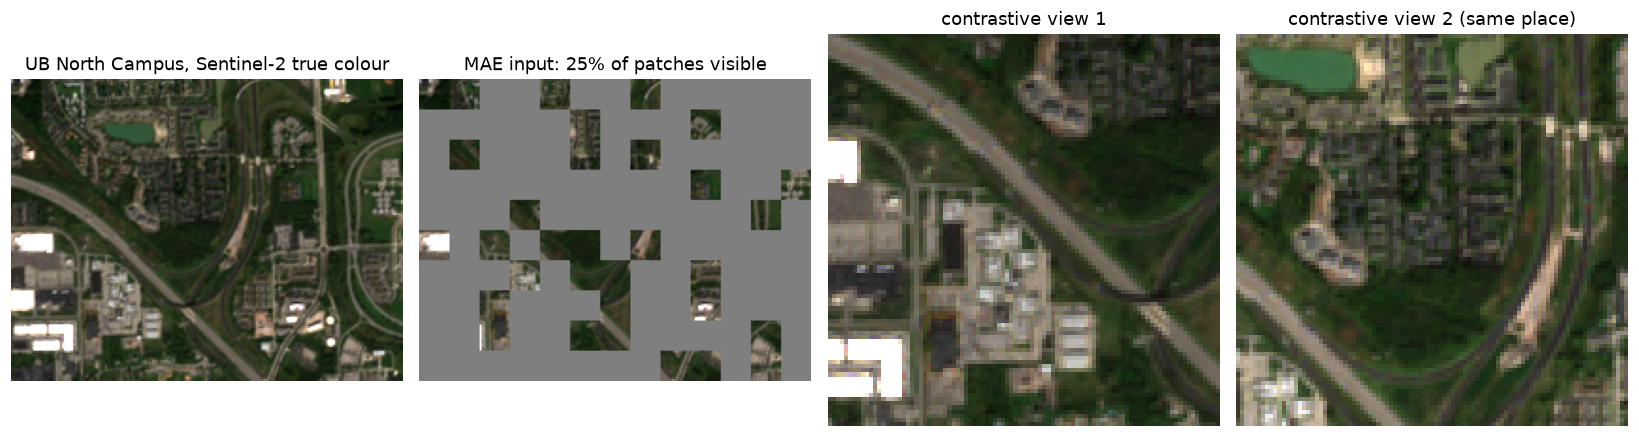

In [3]:
rng = np.random.default_rng(SEED)  # random generator
img = rgb(ub)[:160, :208]  # campus image cut to whole 16 px patches
P = 16  # patch size in pixels
grid = (img.shape[0] // P, img.shape[1] // P)  # patches per column and row
keep = np.zeros(grid[0] * grid[1], bool)  # visible patches
keep[rng.choice(keep.size, keep.size // 4, replace=False)] = True  # MAE keeps one patch in four
keep = keep.reshape(grid)  # back to the patch grid
masked = img.copy()  # masked copy of the image
for (r, c), k in np.ndenumerate(keep):  # every patch
    if not k:  # hidden patch
        masked[r * P:(r + 1) * P, c * P:(c + 1) * P] = 0.5  # grey it out

def view(im, rng):  # a random contrastive view: crop, flip and brightness change
    h, w = im.shape[:2]  # image size
    s = rng.integers(80, 120)  # crop size
    r0, c0 = rng.integers(0, h - s), rng.integers(0, w - s)  # crop corner
    v = im[r0:r0 + s, c0:c0 + s]  # the crop
    v = v[:, ::-1] if rng.random() < 0.5 else v  # random horizontal flip
    return np.clip(v * rng.uniform(0.7, 1.3), 0, 1)  # random brightness

fig, ax = plt.subplots(1, 4, figsize=(15, 4))  # four panels
ax[0].imshow(img); ax[0].set_title("UB North Campus, Sentinel-2 true colour")  # original
ax[1].imshow(masked); ax[1].set_title(f"MAE input: {keep.mean():.0%} of patches visible")  # masked input
ax[2].imshow(view(img, rng)); ax[2].set_title("contrastive view 1")  # first view
ax[3].imshow(view(img, rng)); ax[3].set_title("contrastive view 2 (same place)")  # second view
for a in ax:  # every panel
    a.axis("off")  # hide the axes
plt.tight_layout(); plt.show()  # draw

The MAE must infer roads, roofs and lawns under the grey patches from their surroundings, which
forces it to learn spatial and spectral structure. The contrastive model must recognise that the
two crops show the same place despite the flip and brightness change, so it learns features that
ignore those nuisances.

## The model catalog

`fm.list_models()` returns one row per model: provider, year, input modalities, whether it handles
time, embedding size, parameters, how GeoLattice loads it and what it is used for.

In [4]:
cat = fm.list_models()  # the full catalog
print(len(cat), "models |", int(cat["loadable"].sum()), "loadable with fm.load_model")  # counts
pd.DataFrame({"models": cat.groupby("category").size(),  # models per category
              "loadable": cat.groupby("category")["loadable"].sum()}
             ).rename(index=fm.CATEGORIES)  # long category names

45 models | 24 loadable with fm.load_model


,models,loadable
category,,
"Multi-sensor and any-modality encoders (optical, SAR, DEM, any band set)",12,8
"Multispectral optical encoders (Sentinel-2, Landsat, HLS)",13,11
Pixel time series models and precomputed global embedding products,3,0
"Very high resolution (aerial, sub-metre satellite) encoders and segmenters",4,2
"Image-text models for retrieval, zero-shot classification and chat",8,3
Weather and Earth system emulators on gridded fields,5,0


In [5]:
cat[["category", "provider", "year", "modalities", "temporal", "embed_dim", "params", "loader"]]  # main columns

,category,provider,year,modalities,temporal,embed_dim,params,loader
name,,,,,,,,
prithvi-eo-1.0-100m,optical,NASA / IBM,2023,optical,True,768.0,100M,terratorch
prithvi-eo-2.0-300m,optical,NASA / IBM,2024,optical,True,1024.0,300M,terratorch
prithvi-eo-2.0-300m-tl,optical,NASA / IBM,2024,optical,True,1024.0,300M,terratorch
prithvi-eo-2.0-600m,optical,NASA / IBM,2024,optical,True,1280.0,600M,terratorch
satmae,optical,Stanford,2022,optical,True,1024.0,300M,adapter
scale-mae,optical,UC Berkeley,2023,optical,False,1024.0,300M,torchgeo
ssl4eo-s12-resnet18-moco,optical,TUM / DLR,2022,optical,False,512.0,11M,torchgeo
ssl4eo-s12-resnet50-moco,optical,TUM / DLR,2022,optical,False,2048.0,25M,torchgeo
ssl4eo-s12-vits16-dino,optical,TUM / DLR,2022,optical,False,384.0,22M,torchgeo


The `loader` column says how a model is obtained. `torchgeo`, `terratorch`, `open_clip`,
`torch.hub` and `transformers` models download their weights on the first `fm.load_model` call.
`earthengine` is AlphaEarth, which is a dataset rather than a model to run. `adapter` models need a
local checkpoint, and `external` models are listed with their weights and references but run
through their authors' code.

The release years show how quickly the field has grown, and how it moved from single-sensor
optical encoders to multi-sensor and any-band models.

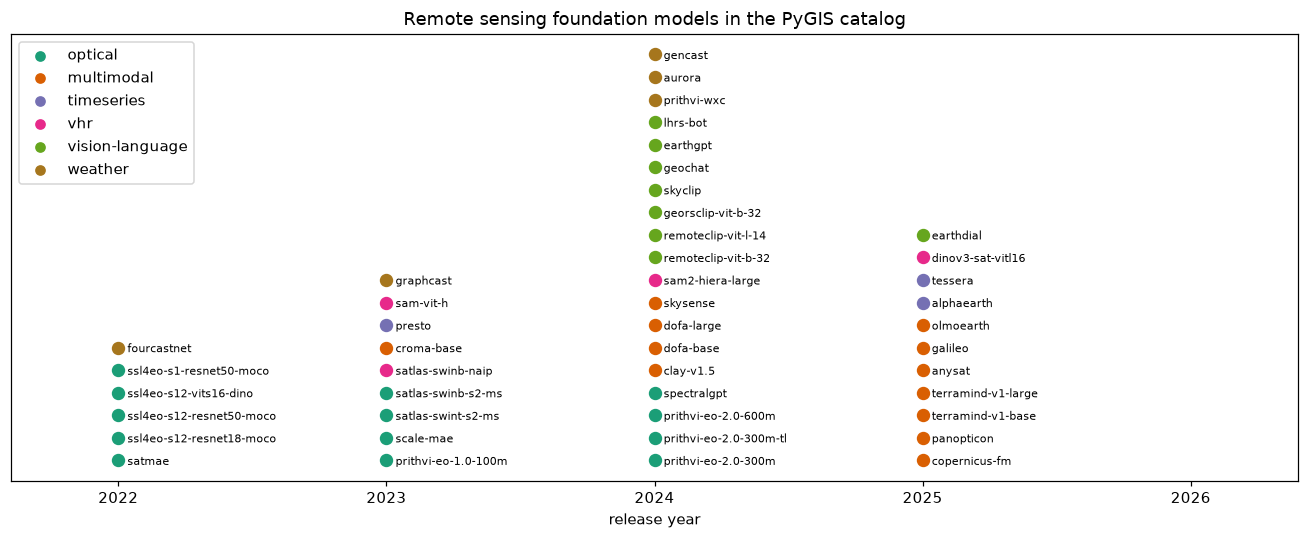

In [6]:
colors = dict(zip(fm.CATEGORIES, ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#a6761d"]))  # colour per category
fig, ax = plt.subplots(figsize=(12, 5))  # one panel
offset = cat.groupby("year").cumcount()  # stack models released in the same year
for name, row in cat.iterrows():  # every model
    ax.scatter(row["year"], offset[name], s=60, color=colors[row["category"]])  # one dot
    ax.annotate(name, (row["year"], offset[name]), xytext=(6, -3), textcoords="offset points", fontsize=7)  # its name
for c, col in colors.items():  # legend entries
    ax.scatter([], [], color=col, label=c)  # empty handle with the category colour
ax.legend(loc="upper left"); ax.set_xlabel("release year"); ax.set_yticks([])  # labels
ax.set_xlim(2021.6, 2026.4); ax.set_title("Remote sensing foundation models in the GeoLattice catalog")  # limits and title
plt.tight_layout(); plt.show()  # draw

Filters narrow the list. Models that accept SAR, models with time support, and the vision-language
models are three common questions.

In [7]:
print("Accept SAR:", ", ".join(fm.list_models(modality="sar").index))  # SAR-capable models
print("Handle time:", ", ".join(fm.list_models(temporal=True, loadable=True).index))  # loadable temporal models
fm.list_models("vision-language")[["provider", "params", "loader", "use_cases"]]  # image-text models

Accept SAR: ssl4eo-s1-resnet50-moco, clay-v1.5, dofa-base, dofa-large, croma-base, copernicus-fm, panopticon, terramind-v1-base, terramind-v1-large, anysat, galileo, olmoearth, skysense, alphaearth, presto, tessera, earthgpt, earthdial
Handle time: prithvi-eo-1.0-100m, prithvi-eo-2.0-300m, prithvi-eo-2.0-300m-tl, prithvi-eo-2.0-600m, copernicus-fm, anysat


,provider,params,loader,use_cases
name,,,,
remoteclip-vit-b-32,Liu et al.,151M,open_clip,zero-shot scene classification; retrieval
remoteclip-vit-l-14,Liu et al.,428M,open_clip,retrieval
georsclip-vit-b-32,Zhang et al.,151M,open_clip,zero-shot classification; retrieval
skyclip,Wang et al.,428M,external,fine-grained zero-shot classification
geochat,MBZUAI,7B,external,visual question answering; grounded description
earthgpt,Zhang et al.,13B,external,captioning; VQA; detection
lhrs-bot,Nanjing University,7B,external,VQA; scene reasoning
earthdial,MBZUAI,4B,external,change description; multispectral VQA


`fm.model_info` returns every field of one entry, including the expected inputs, the weights and
the reference. The inputs line is the first thing to check: it says which bands, scaling and chip
size the model was trained with.

In [8]:
info = fm.model_info("prithvi-eo-2.0-300m")  # one catalog entry
{k: info[k] for k in ("provider", "architecture", "inputs", "embed_dim", "weights", "reference")}  # key fields

{'provider': 'NASA / IBM',
 'architecture': 'ViT-L MAE, 3-D patch embedding',
 'inputs': 'HLS 6 bands, 224 px, 1 to 4 time steps',
 'embed_dim': 1024,
 'weights': 'ibm-nasa-geospatial/Prithvi-EO-2.0-300M',
 'reference': 'Szwarcman et al. 2024, arXiv:2412.02732'}

## Choosing a model for a task

`fm.recommend` returns a short list of models to try first for a task. A sensor filter drops
models that cannot read that sensor. The list is a starting point from benchmarks and practice; the
comparison on your own data (notebook 09_11_13) decides.

In [9]:
tasks = ["covariates", "segmentation", "timeseries", "multisensor", "vhr", "zero-shot", "change"]  # common tasks
pd.DataFrame({t: pd.Series(fm.recommend(t)["name"].tolist()) for t in tasks}).fillna("")  # top models per task

,covariates,segmentation,timeseries,multisensor,vhr,zero-shot,change
0,alphaearth,prithvi-eo-2.0-300m,presto,dofa-base,dinov3-sat-vitl16,remoteclip-vit-b-32,alphaearth
1,clay-v1.5,terramind-v1-base,galileo,copernicus-fm,satlas-swinb-naip,georsclip-vit-b-32,prithvi-eo-2.0-300m
2,presto,satlas-swinb-s2-ms,prithvi-eo-2.0-300m-tl,panopticon,sam2-hiera-large,skyclip,dofa-base
3,ssl4eo-s12-resnet18-moco,dofa-base,anysat,terramind-v1-base,sam-vit-h,sam2-hiera-large,
4,,,alphaearth,croma-base,,,
5,,,,clay-v1.5,,,


In [10]:
fm.recommend("multisensor", sensor="sentinel-1")  # models that also read SAR

,name,loader,why
rank,,,
1,dofa-base,torchgeo,mixed sensors; unusual band sets; hyperspectral
2,copernicus-fm,torchgeo,Copernicus multi-mission; atmospheric variables
3,panopticon,torchgeo,any sensor embeddings
4,terramind-v1-base,terratorch,missing modality synthesis; multimodal segment...
5,croma-base,torchgeo,optical-SAR fusion; cloudy regions
6,clay-v1.5,adapter,embeddings; similarity search; land cover


## From an image to patch embeddings

DOFA (Xiong et al. 2024) is a ViT-Base whose first layer is generated from the band wavelengths,
so it reads the ten UB bands directly. `fm.load_model("dofa-base")` downloads the weights once;
`embed_raster` standardizes each band, cuts the raster into 224 pixel chips (one chip here, padded
by reflection) and, with `dense=True`, returns the 14 x 14 grid of patch embeddings of each chip
as a georeferenced map. Each cell is a 16 x 16 pixel (160 m) patch.

In [11]:
enc = fm.load_model("dofa-base", device=DEVICE)  # DOFA ViT-Base with MAE weights
t0 = time.perf_counter()  # start the clock
patch = enc.embed_raster(ub, chip_size=224, dense=True)  # (768, y, x) patch embeddings
print(enc, "| wavelengths (nm):", enc.wavelengths)  # model and the band wavelengths it used
print("patch embeddings:", dict(patch.sizes), f"in {time.perf_counter() - t0:.1f} s")  # result size
image_vec = enc.embed_raster(ub, chip_size=224)  # one pooled vector for the whole chip
print("image embedding:", dict(image_vec.sizes))  # one cell of 768 values

FoundationEncoder('dofa-base', loader='torchgeo', embed_dim=768, device=cuda) | wavelengths (nm): [490.0, 560.0, 665.0, 705.0, 740.0, 783.0, 842.0, 865.0, 1610.0, 2190.0]
patch embeddings: {'embedding': 768, 'y': 11, 'x': 14} in 0.2 s
image embedding: {'embedding': 768, 'y': 1, 'x': 1}


The patch map has 11 x 14 cells (the padded part beyond the campus is cropped), each a 768 value
vector. `fm.embedding_rgb` projects the vectors onto their first three principal components and
shows them as colours, so cells the model sees as similar get similar colours.

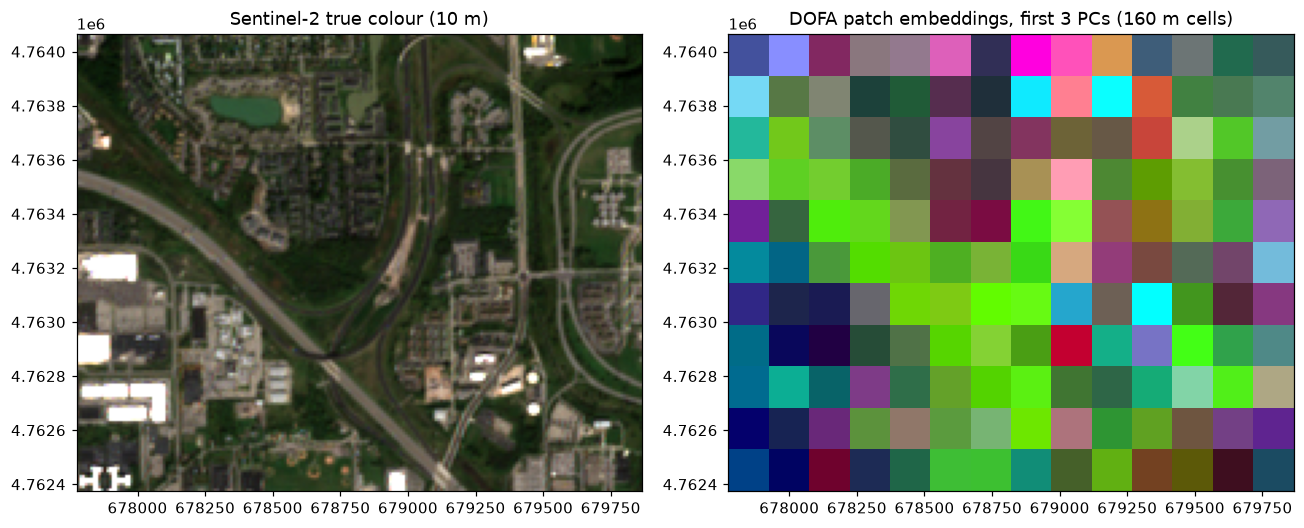

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))  # two panels
ext = [float(ub.x.min()), float(ub.x.max()), float(ub.y.min()), float(ub.y.max())]  # map extent
ax[0].imshow(rgb(ub), extent=ext); ax[0].set_title("Sentinel-2 true colour (10 m)")  # image
pc = fm.embedding_rgb(patch)  # first three principal components as RGB
ax[1].imshow(pc.transpose("y", "x", "band"), extent=ext, interpolation="nearest")  # embedding colours
ax[1].set_title("DOFA patch embeddings, first 3 PCs (160 m cells)")  # title
plt.tight_layout(); plt.show()  # draw

## What the embeddings separate

Each labelled point falls into one 160 m cell. A cell is labelled with the most common class of
its points, kept only when that class covers at least 60 % of them, so mixed cells drop out.

In [13]:
pts = pd.read_csv(UB / "Label_Point_Data" / "point_data.csv")  # labelled pixels
iy = np.abs(patch.y.values[None, :] - pts["y"].values[:, None]).argmin(1)  # nearest cell row
ix = np.abs(patch.x.values[None, :] - pts["x"].values[:, None]).argmin(1)  # nearest cell column
pts["cell"] = iy * patch.sizes["x"] + ix  # cell index of every point
share = pts.groupby("cell")["Landuse"].agg(lambda s: s.value_counts(normalize=True).iloc[0])  # majority share
major = pts.groupby("cell")["Landuse"].agg(lambda s: s.value_counts().index[0])  # majority class
cells = pd.DataFrame({"class": major, "purity": share, "n_points": pts.groupby("cell").size()})  # per-cell table
cells = cells[cells["purity"] >= 0.6]  # keep cells dominated by one class
cells = cells[cells["class"].map(cells["class"].value_counts()) >= 4]  # classes with enough cells for 4 folds
X = patch.values.reshape(patch.sizes["embedding"], -1).T[cells.index]  # embedding of each kept cell
print(len(cells), "labelled cells"); cells["class"].value_counts()  # cells per class

93 labelled cells


class
Building                 29
Parking/road/pavement    24
Tree/bushes              22
Grass                    18
Name: count, dtype: int64

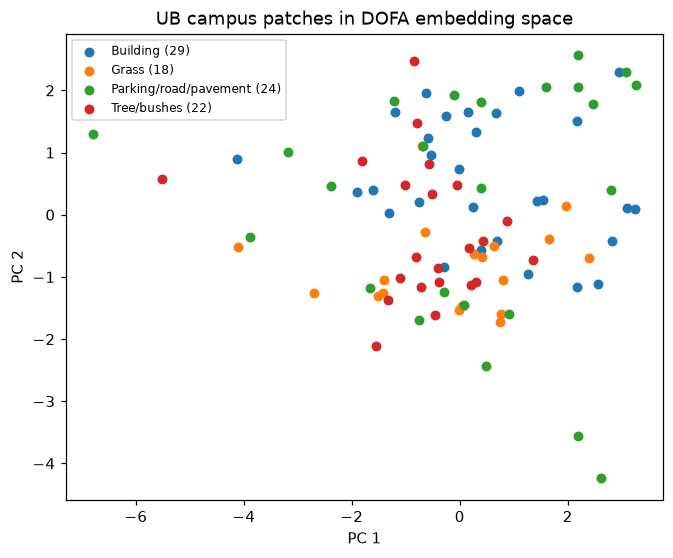

In [14]:
from sklearn.decomposition import PCA  # principal components

Z = PCA(2, random_state=SEED).fit_transform(X)  # 768 values -> 2 for plotting
fig, ax = plt.subplots(figsize=(7, 5.5))  # one panel
for c in sorted(cells["class"].unique()):  # every class
    m = (cells["class"] == c).values  # its cells
    ax.scatter(Z[m, 0], Z[m, 1], s=30, label=f"{c} ({m.sum()})")  # its points
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(fontsize=8)  # labels
ax.set_title("UB campus patches in DOFA embedding space"); plt.show()  # draw

Water covers only two cells of the campus, too few for four cross-validation folds, so it is left
out. The scatter shows how the classes spread in the two directions of largest variance. A linear probe
measures separability in all 768 dimensions. With so few cells the probe uses leave-out folds of
four, and its score is a rough indication, not a benchmark: neighbouring cells are spatially
correlated, which notebook 09_11_04 handles with spatial cross-validation. A logistic regression on
the cell's mean band values is the baseline the embeddings have to beat.

In [15]:
means = ub.coarsen(y=16, x=16, boundary="pad").mean()  # mean reflectance per 160 m cell
B = means.values.reshape(means.sizes["band"], -1).T  # (cells, 10 bands)
B = np.nan_to_num(B[: patch.sizes["y"] * patch.sizes["x"]])  # same cell order as the patch map
y = cells["class"].values  # cell classes
probe = fm.linear_probe(X, y, cv=4)  # DOFA embeddings
base = fm.linear_probe(B[cells.index], y, cv=4)  # band means
pd.DataFrame({"DOFA patch embeddings": probe["mean"], "mean band values": base["mean"]}).round(3)  # accuracy and macro F1

,DOFA patch embeddings,mean band values
accuracy,0.613,0.527
f1_macro,0.602,0.519


The DOFA embeddings separate the four classes better than the mean band values of the same cells,
because each embedding also describes the arrangement of roofs, roads and trees inside its 160 m
patch, not just its average colour. Read the numbers with care all the same: with about ninety
cells and random folds the scores move by several points from one split to another, and
neighbouring cells share information. The rest of the chapter uses larger labelled sets, spatial
folds and several models, so that such comparisons become meaningful.

## Summary and exercises

### Summary

- A foundation model is pretrained once without labels and adapted to many tasks; its encoder turns
  an image or a patch into an embedding.
- Pretraining objectives include masked autoencoding, contrastive learning, self-distillation, joint
  embedding prediction, generative any-to-any models, image-text alignment and embedding fields.
- Satellite data differ from photographs in bands, sensors, ground sample distance, time and
  geolocation; wavelength-aware, GSD-aware and temporal models address these.
- Models can be used as frozen feature extractors, fine-tuned, run zero-shot, or replaced by
  precomputed embeddings. A linear probe measures what frozen embeddings know.
- Benchmarks show no single best model and strong supervised baselines, so every comparison needs a
  baseline and spatial cross-validation.
- `fm.list_models`, `fm.recommend` and `fm.load_model` give one interface to 45 catalogued models,
  24 of them loadable.

### Exercises

1. Mask 50 % and 90 % of the patches in the MAE figure. Which campus features can you still infer?
2. List the catalog models that accept hyperspectral data. What do their input layers have in common?
3. Load `ssl4eo-s12-resnet18-moco` and check its `inputs` field. Which three Sentinel-2 bands does the
   UB stack lack, and what would you do about them?
4. Compute the image embedding with `pool="cls"` instead of the default mean of the patch tokens
   (`enc.embed_raster(ub, pool="cls")`) and compare the two vectors with a cosine similarity.
5. Run `fm.recommend("hyperspectral")` and read the model cards of the first two results.

### References

- Bommasani, R. et al. (2021). On the opportunities and risks of foundation models. arXiv:2108.07258.
- He, K. et al. (2022). Masked autoencoders are scalable vision learners. CVPR.
- Lacoste, A. et al. (2023). GEO-Bench: toward foundation models for Earth monitoring. NeurIPS Datasets and Benchmarks.
- Marsocci, V. et al. (2024). PANGAEA: a global and inclusive benchmark for geospatial foundation models. arXiv:2412.04204.
- Wang, Y. et al. (2023). SSL4EO-S12: a large-scale multimodal, multitemporal dataset for self-supervised learning in Earth observation. IEEE GRSM.
- Xiong, Z. et al. (2024). Neural plasticity-inspired multimodal foundation model for Earth observation (DOFA). arXiv:2403.15356.